# Milestone 3 — Exploratory Data Analysis (EDA) trên Tập Phát Triển

**Đề tài:** *An Empirical Study of Machine Learning Models for Vehicle Loan Default Prediction*  
**Nguyên tắc chống rò rỉ dữ liệu:** Toàn bộ quá trình khám phá phân phối, mối liên hệ với biến mục tiêu `loan_default` và tìm kiếm mẫu hình đặc trưng trong notebook này chỉ được thực hiện trên **Tập Phát Triển (Primary Development Set: `DisbursalDate <= 2018-10-22`, $n = 182{,}501$)**. Tập **Locked OOT Test Set (`>= 2018-10-23`, $n = 50{,}653$)** được cô lập hoàn toàn và **không** được truy cập nhãn hay phân tích trong EDA.

In [1]:
import json
import os
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".matplotlib_cache"))

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

from src.data.load_data import load_config, parse_disbursal_dates, parse_dob_century_safe, parse_duration_months_series
from src.data.splits import load_split_frames

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 140, "savefig.dpi": 300, "axes.titlesize": 11, "axes.titleweight": "bold"})

cfg = load_config()
FIG_DIR = ROOT / cfg["paths"]["figures_dir"]
TABLES_DIR = ROOT / cfg["paths"]["tables_dir"]
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

train_df, val_df, test_df, dev_df, split_df = load_split_frames("oot", cfg)

# Strictly discard test_df reference to guarantee zero accidental inspection in EDA
del test_df

print(f"Primary Development Set shape (used for EDA): {dev_df.shape}")
print(f"  - Train fold pool: {len(train_df):,} rows")
print(f"  - Validation holdout: {len(val_df):,} rows")
print(f"Locked OOT Test Set: isolated ({int((split_df['split'] == 'test').sum()):,} rows, NOT touched in EDA).")

Primary Development Set shape (used for EDA): (182501, 41)
  - Train fold pool: 146,000 rows
  - Validation holdout: 36,501 rows
Locked OOT Test Set: isolated (50,653 rows, NOT touched in EDA).


In [2]:
# Deterministic parsing on dev_df only (stateless)
dev = dev_df.copy()
dev["disb_dt"] = parse_disbursal_dates(dev["DisbursalDate"])
dev["dob_dt"] = parse_dob_century_safe(dev["Date.of.Birth"], reference_years=dev["disb_dt"].dt.year)
dev["age_at_disbursal"] = (dev["disb_dt"] - dev["dob_dt"]).dt.days / 365.25
dev["avg_acct_age_months"] = parse_duration_months_series(dev["AVERAGE.ACCT.AGE"])
dev["credit_history_months"] = parse_duration_months_series(dev["CREDIT.HISTORY.LENGTH"])
dev["Employment.Type_clean"] = dev["Employment.Type"].fillna("MISSING")
dev["has_bureau_score"] = (dev["PERFORM_CNS.SCORE"] >= 300).astype(int)

n_dev = len(dev)
n_pos_dev = int(dev["loan_default"].sum())
n_neg_dev = n_dev - n_pos_dev
dev_default_rate = n_pos_dev / n_dev
print(f"Dev Default Rate: {dev_default_rate*100:.4f}% ({n_pos_dev:,} defaults / {n_neg_dev:,} non-defaults)")
print(f"Dev DisbursalDate range: {dev['disb_dt'].min().date()} .. {dev['disb_dt'].max().date()}")

Dev Default Rate: 20.6295% (37,649 defaults / 144,852 non-defaults)
Dev DisbursalDate range: 2018-08-01 .. 2018-10-22


## 1. Phân phối Biến Mục Tiêu, Mất Cân Bằng Lớp và Biên Thời Gian Chia Tập

cell_4:32: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.


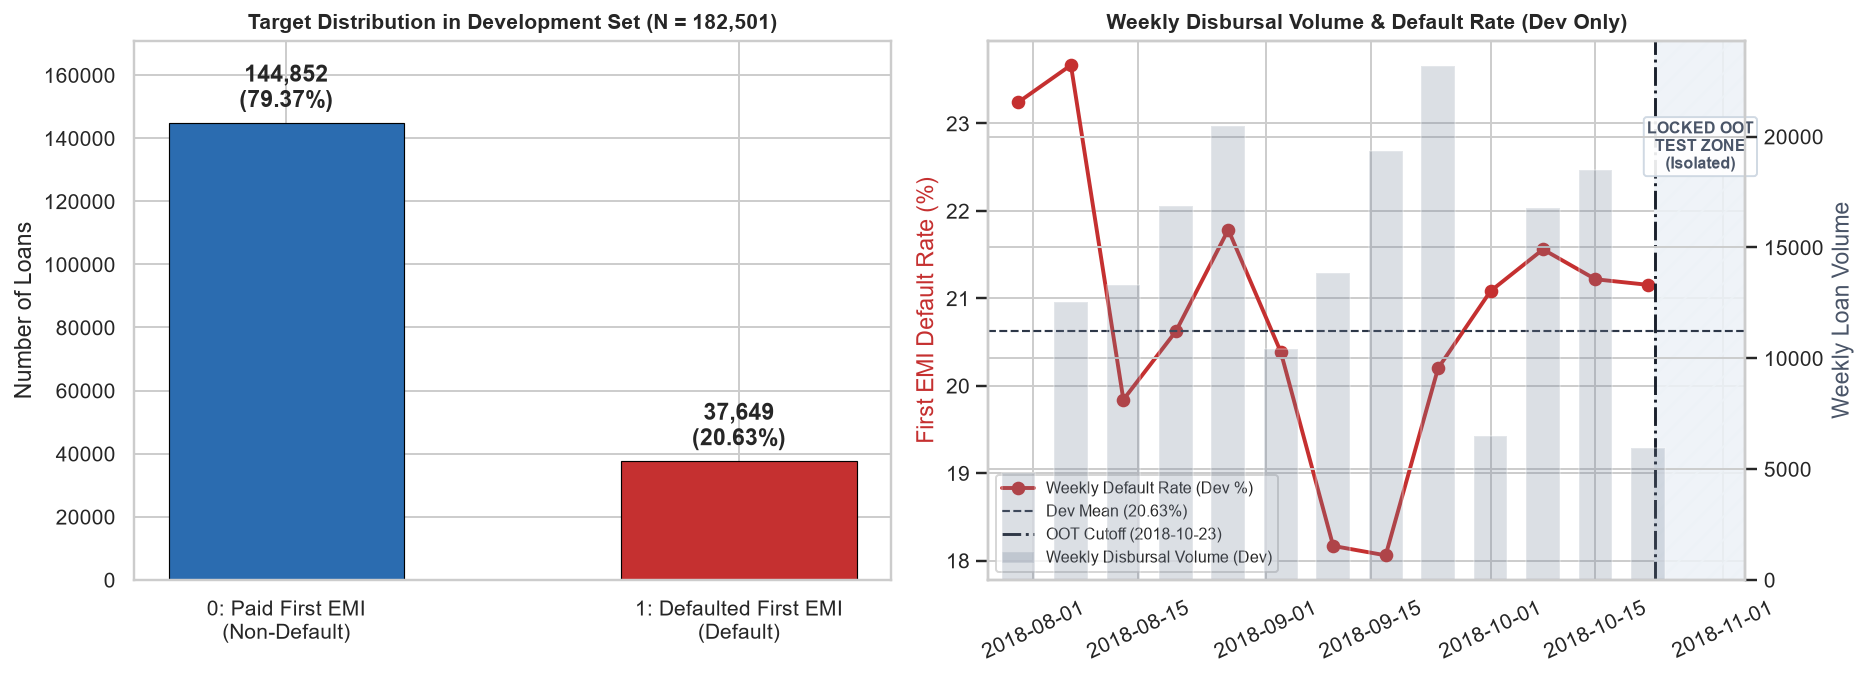

In [3]:
def wilson_ci(k: np.ndarray, n: np.ndarray, z: float = 1.96) -> tuple[np.ndarray, np.ndarray]:
    p = k / n
    denom = 1.0 + z**2 / n
    center = (p + z**2 / (2.0 * n)) / denom
    half = (z * np.sqrt((p * (1.0 - p) + z**2 / (4.0 * n)) / n)) / denom
    return np.clip(center - half, 0, 1), np.clip(center + half, 0, 1)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.0))

# Left: Class distribution in Dev Set
counts = [n_neg_dev, n_pos_dev]
labels = ["0: Paid First EMI\n(Non-Default)", "1: Defaulted First EMI\n(Default)"]
bars = axes[0].bar(labels, counts, color=["#2b6cb0", "#c53030"], width=0.52, edgecolor="black", linewidth=0.6)
axes[0].set_title(f"Target Distribution in Development Set (N = {n_dev:,})")
axes[0].set_ylabel("Number of Loans")
axes[0].set_ylim(0, max(counts) * 1.18)
for b, c in zip(bars, counts):
    axes[0].text(b.get_x() + b.get_width() / 2, c + max(counts) * 0.02, f"{c:,}\n({c/n_dev*100:.2f}%)", ha="center", va="bottom", fontweight="bold")

# Right: Weekly volume & default rate inside Dev, with Locked Test region masked
dev["week_start"] = dev["disb_dt"].dt.to_period("W-SUN").apply(lambda p: p.start_time)
wk = dev.groupby("week_start").agg(n=("loan_default", "count"), k=("loan_default", "sum")).reset_index()
wk["rate_pct"] = wk["k"] / wk["n"] * 100.0

ax_r = axes[1]
ax_r2 = ax_r.twinx()
ax_r2.bar(wk["week_start"], wk["n"], width=4.5, alpha=0.25, color="#718096", label="Weekly Disbursal Volume (Dev)")
ax_r.plot(wk["week_start"], wk["rate_pct"], color="#c53030", marker="o", linewidth=2.0, label="Weekly Default Rate (Dev %)")
ax_r.axhline(dev_default_rate * 100, color="#2d3748", linestyle="--", linewidth=1.1, label=f"Dev Mean ({dev_default_rate*100:.2f}%)")
cutoff_dt = pd.Timestamp(cfg["splits"]["oot_cutoff_date"])
ax_r.axvline(cutoff_dt, color="#1a202c", linestyle="-.", linewidth=1.5, label="OOT Cutoff (2018-10-23)")
ax_r.axvspan(cutoff_dt, pd.Timestamp("2018-11-04"), color="#edf2f7", alpha=0.85, hatch="//", edgecolor="#a0aec0")
ax_r.text(cutoff_dt + pd.Timedelta(days=6), wk["rate_pct"].max() * 0.95, "LOCKED OOT\nTEST ZONE\n(Isolated)", fontsize=8.0, fontweight="bold", color="#4a5568", ha="center", bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor="#cbd5e0", alpha=0.9))
ax_r.set_xlim(wk["week_start"].min() - pd.Timedelta(days=4), pd.Timestamp("2018-11-04"))
ax_r.set_title("Weekly Disbursal Volume & Default Rate (Dev Only)")
ax_r.set_ylabel("First EMI Default Rate (%)", color="#c53030")
ax_r2.set_ylabel("Weekly Loan Volume", color="#4a5568")
ax_r.tick_params(axis="x", rotation=25)
l1, lb1 = ax_r.get_legend_handles_labels()
l2, lb2 = ax_r2.get_legend_handles_labels()
ax_r.legend(l1 + l2, lb1 + lb2, loc="lower left", fontsize=8)

fig.tight_layout()
fig.savefig(FIG_DIR / "eda_01_target_and_splits.png", bbox_inches="tight")
plt.show()

**Diễn giải Hình `eda_01_target_and_splits.png`:**
- **Biểu đồ cho thấy gì:** Tập Development ($N = 182{,}501$) có `37,649` ca vỡ nợ (`20.63%`) và `144,852` ca trả đúng hạn (`79.37%`), tương ứng tỷ lệ mất cân bằng `3.85 : 1`. Theo thời gian nội bộ tập Dev, tỷ lệ vỡ nợ dao động từ `~18.1%` (giữa tháng 9) lên `~23.7%` (đầu tháng 8) và có dấu hiệu nhích dần trong tháng 10.
- **Tại sao quan trọng:** Mất cân bằng mức trung bình (`~20.6%`) đủ lớn để khiến `Accuracy` gây hiểu lầm (`79.4%` nếu dự đoán toàn 0) nhưng cũng đủ dồi dào mẫu dương tính (`37,649` ca) để mô hình học trực tiếp mà không cần vội tái lấy mẫu SMOTE. Đường ranh giới `2018-10-23` xác nhận vùng dữ liệu kiểm thử OOT nằm tách biệt hoàn toàn phía sau.
- **Có thể và KHÔNG thể kết luận gì:** Có thể khẳng định biến động tỷ lệ rủi ro theo tuần tồn tại rõ ràng, ủng hộ việc dùng kiểm định OOT song song với Random Split (`RQ3`). **Không thể kết luận** nguyên nhân khiến tháng 9 thấp hơn tháng 8/10 từ dữ liệu quan sát đơn thuần (có thể do chính sách khuyến mãi, hỗn hợp kênh đại lý hoặc mùa vụ).

## 2. Phân Bố Các Biến Số Chủ Chốt và Ngoại Lai

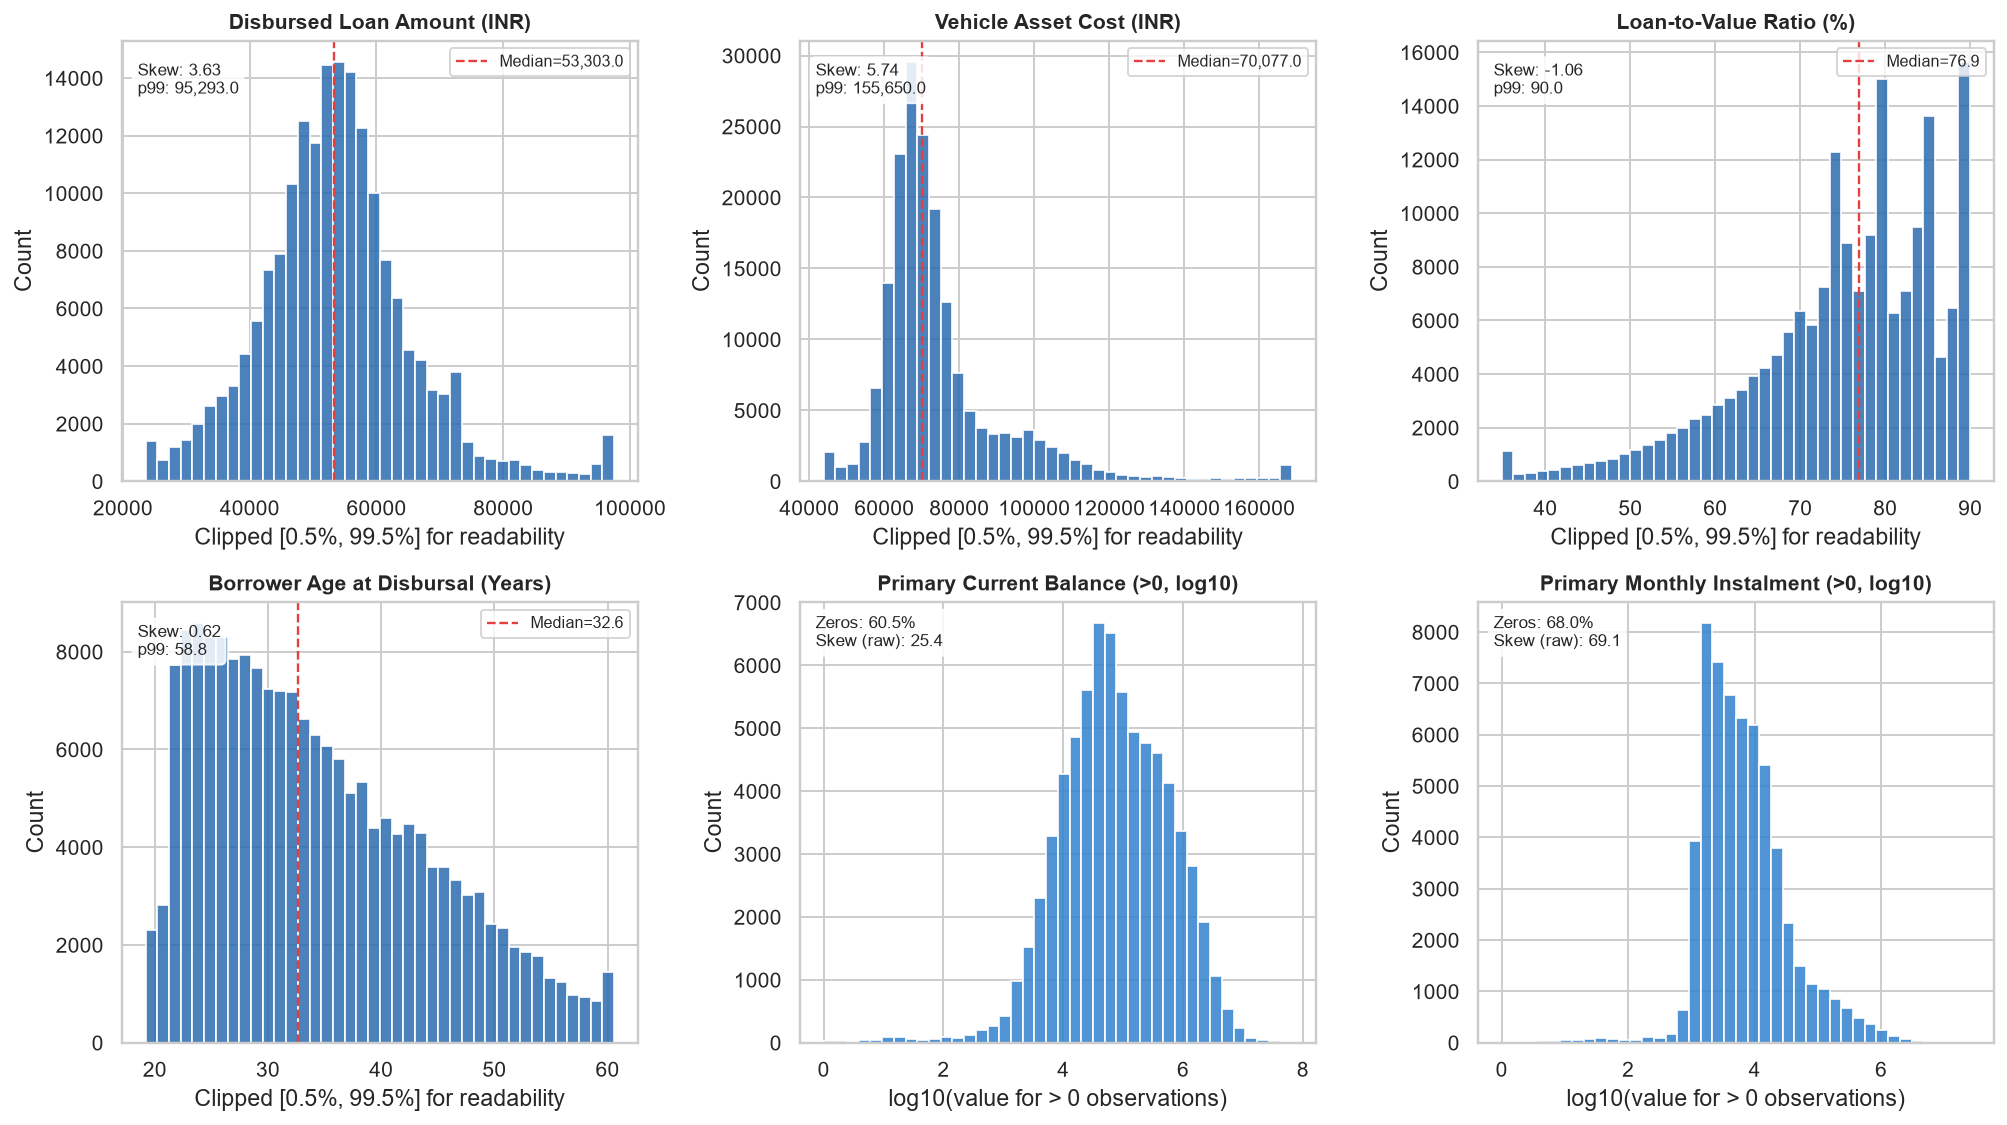

In [4]:
num_specs = [
    ("disbursed_amount", dev["disbursed_amount"], False, "Disbursed Loan Amount (INR)"),
    ("asset_cost", dev["asset_cost"], False, "Vehicle Asset Cost (INR)"),
    ("ltv", dev["ltv"], False, "Loan-to-Value Ratio (%)"),
    ("age_at_disbursal", dev["age_at_disbursal"], False, "Borrower Age at Disbursal (Years)"),
    ("PRI.CURRENT.BALANCE", dev["PRI.CURRENT.BALANCE"], True, "Primary Current Balance (>0, log10)"),
    ("PRIMARY.INSTAL.AMT", dev["PRIMARY.INSTAL.AMT"], True, "Primary Monthly Instalment (>0, log10)"),
]

fig, axes = plt.subplots(2, 3, figsize=(14.5, 8.2))
num_summary = {}
for ax, (col_name, series, log_pos, title) in zip(axes.ravel(), num_specs):
    s = series.dropna()
    sk = float(stats.skew(s))
    med = float(s.median())
    p99 = float(np.percentile(s, 99))
    pct_zero = float((s == 0).mean() * 100)
    num_summary[col_name] = {
        "median": round(med, 2),
        "p99": round(p99, 2),
        "max": round(float(s.max()), 2),
        "skewness": round(sk, 2),
        "pct_zero": round(pct_zero, 2),
    }
    if log_pos:
        s_pos = np.log10(s[s > 0])
        ax.hist(s_pos, bins=40, color="#3182ce", alpha=0.85, edgecolor="white")
        ax.set_xlabel("log10(value for > 0 observations)")
        ax.text(0.03, 0.90, f"Zeros: {pct_zero:.1f}%\nSkew (raw): {sk:.1f}", transform=ax.transAxes, fontsize=8.5, bbox=dict(boxstyle="round", facecolor="white", alpha=0.85))
    else:
        lo, hi = np.percentile(s, [0.5, 99.5])
        ax.hist(s.clip(lo, hi), bins=40, color="#2b6cb0", alpha=0.85, edgecolor="white")
        ax.axvline(med, color="#e53e3e", linestyle="--", linewidth=1.2, label=f"Median={med:,.1f}")
        ax.set_xlabel("Clipped [0.5%, 99.5%] for readability")
        ax.legend(fontsize=8, loc="upper right")
        ax.text(0.03, 0.88, f"Skew: {sk:.2f}\np99: {p99:,.1f}", transform=ax.transAxes, fontsize=8.5, bbox=dict(boxstyle="round", facecolor="white", alpha=0.85))
    ax.set_title(title)
    ax.set_ylabel("Count")

fig.tight_layout()
fig.savefig(FIG_DIR / "eda_02_numerical_distributions_and_outliers.png", bbox_inches="tight")
plt.show()

**Diễn giải Hình `eda_02_numerical_distributions_and_outliers.png`:**
- **Biểu đồ cho thấy gì:** Các biến tiền tệ lịch sử tín dụng (`PRI.CURRENT.BALANCE`, `PRIMARY.INSTAL.AMT`) bị **dồn không rất mạnh** (`60.5%–68.3%` bằng 0) và có đuôi phải cực dài (skewness hàng chục đến hàng trăm), trong khi `disbursed_amount` và `asset_cost` lệch phải vừa phải, `ltv` tập trung cao ở vùng `70%–90%` (trung vị `~76.7%`), và `age_at_disbursal` sau sửa thế kỷ phân bố trơn trong khoảng `18–69` tuổi (trung vị `~32.7` tuổi).
- **Tại sao quan trọng:** Độ lệch đuôi cực đại khiến các mô hình tuyến tính (`LogisticRegression`) hoặc mạng nơ-ron (`MLP`) bị chi phối bởi vài điểm ngoại lai nếu không áp dụng `Winsorization` + `SignedLog1p` + `RobustScaler`. Ngược lại, `ltv` bị chặn cận trên quanh `90–95%` phản ánh quy định hạn mức cho vay tối đa.
- **Có thể và KHÔNG thể kết luận gì:** Có thể khẳng định cần biến đổi phi tuyến (`signed_log1p`) và chuẩn hóa kháng ngoại lai cho biến tiền tệ ở nhánh tuyến tính/MLP. **Không thể kết luận** các điểm giá trị rất lớn (như hạn mức hàng chục triệu INR) là lỗi nhập liệu — chúng có thể là khách hàng doanh nghiệp/xe tải thương mại, do đó nên **cắt ngưỡng Winsorize** thay vì xóa dòng.

## 3. Phân Bố Biến Phân Loại, Giá Trị Thiếu (`Employment.Type`) và Địa Lý/Hãng Xe

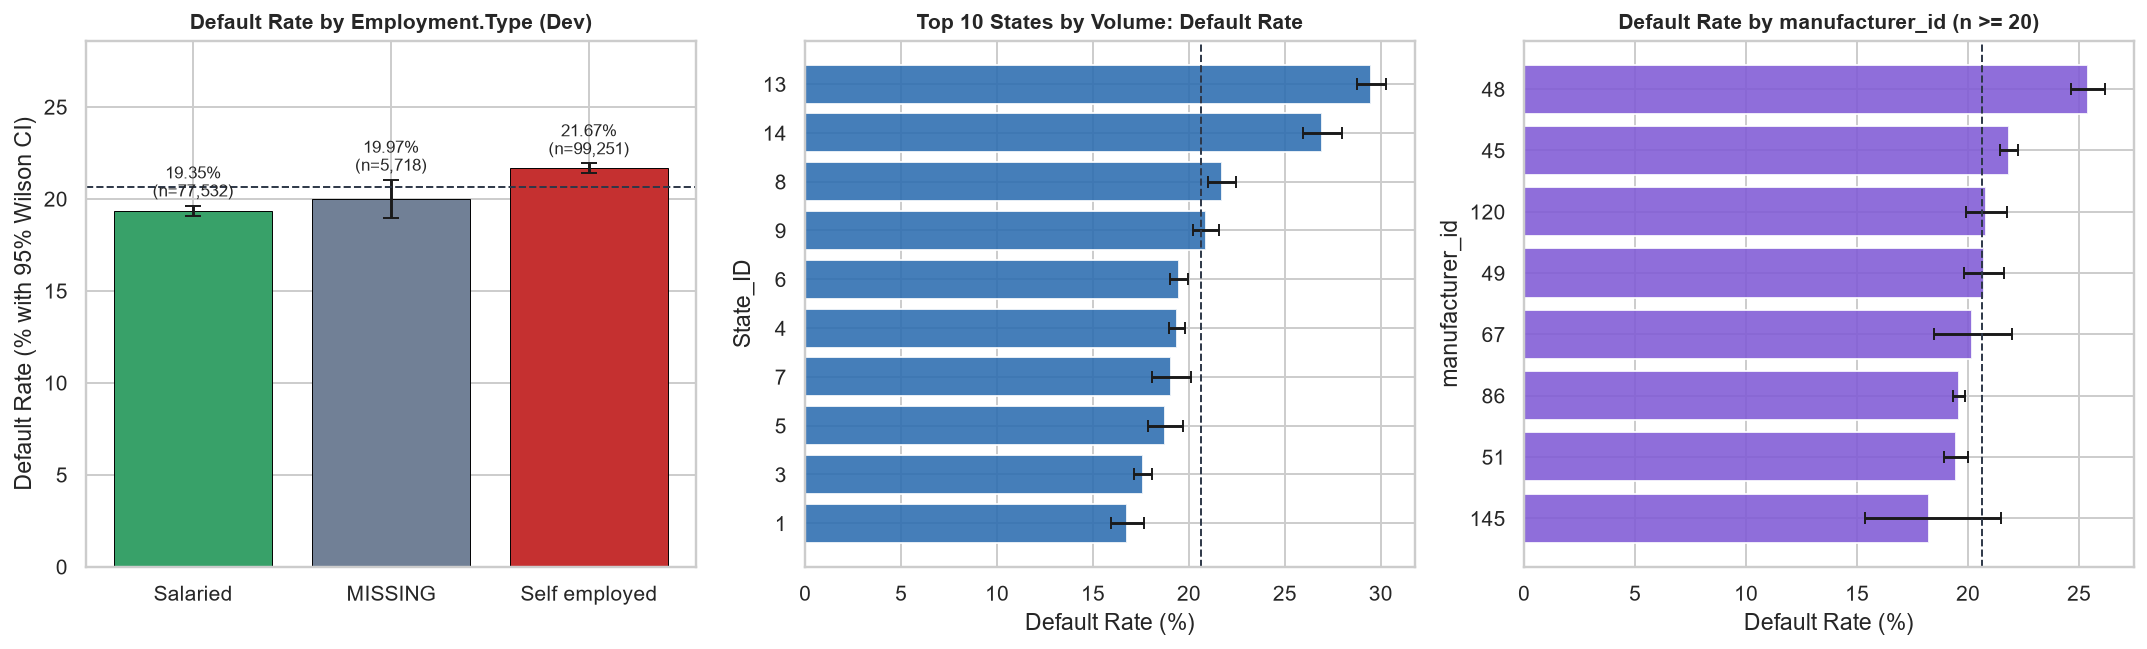

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.8))

# Panel 1: Employment.Type including MISSING
emp = dev.groupby("Employment.Type_clean").agg(n=("loan_default", "count"), k=("loan_default", "sum")).reset_index()
emp["rate"] = emp["k"] / emp["n"] * 100.0
lo, hi = wilson_ci(emp["k"].to_numpy(), emp["n"].to_numpy())
emp["err_lo"] = emp["rate"] - lo * 100.0
emp["err_hi"] = hi * 100.0 - emp["rate"]
emp = emp.sort_values("rate")

axes[0].bar(emp["Employment.Type_clean"], emp["rate"], yerr=[emp["err_lo"], emp["err_hi"]], capsize=4, color=["#38a169", "#718096", "#c53030"], edgecolor="black", linewidth=0.5)
axes[0].axhline(dev_default_rate * 100, color="#2d3748", linestyle="--", linewidth=1.0)
axes[0].set_title("Default Rate by Employment.Type (Dev)")
axes[0].set_ylabel("Default Rate (% with 95% Wilson CI)")
axes[0].set_ylim(0, emp["rate"].max() * 1.32)
for idx, r in enumerate(emp.itertuples()):
    axes[0].text(idx, r.rate + r.err_hi + 0.5, f"{r.rate:.2f}%\n(n={r.n:,})", ha="center", fontsize=8.5)

# Panel 2: Top 10 State_ID by volume
st = dev.groupby("State_ID").agg(n=("loan_default", "count"), k=("loan_default", "sum")).reset_index()
st_top = st.sort_values("n", ascending=False).head(10).sort_values("k", ascending=True)
st_top["rate"] = st_top["k"] / st_top["n"] * 100.0
st_top = st_top.sort_values("rate")
lo_s, hi_s = wilson_ci(st_top["k"].to_numpy(), st_top["n"].to_numpy())
axes[1].barh(st_top["State_ID"].astype(str), st_top["rate"], xerr=[st_top["rate"] - lo_s*100, hi_s*100 - st_top["rate"]], capsize=3, color="#2b6cb0", alpha=0.88)
axes[1].axvline(dev_default_rate * 100, color="#2d3748", linestyle="--", linewidth=1.0)
axes[1].set_title("Top 10 States by Volume: Default Rate")
axes[1].set_xlabel("Default Rate (%)")
axes[1].set_ylabel("State_ID")

# Panel 3: All 11 manufacturer_id
mfg = dev.groupby("manufacturer_id").agg(n=("loan_default", "count"), k=("loan_default", "sum")).reset_index()
mfg["rate"] = mfg["k"] / mfg["n"] * 100.0
mfg = mfg[mfg["n"] >= 20].sort_values("rate")
lo_m, hi_m = wilson_ci(mfg["k"].to_numpy(), mfg["n"].to_numpy())
axes[2].barh(mfg["manufacturer_id"].astype(str), mfg["rate"], xerr=[mfg["rate"] - lo_m*100, hi_m*100 - mfg["rate"]], capsize=3, color="#805ad5", alpha=0.88)
axes[2].axvline(dev_default_rate * 100, color="#2d3748", linestyle="--", linewidth=1.0)
axes[2].set_title("Default Rate by manufacturer_id (n >= 20)")
axes[2].set_xlabel("Default Rate (%)")
axes[2].set_ylabel("manufacturer_id")

fig.tight_layout()
fig.savefig(FIG_DIR / "eda_03_categorical_and_missing_target_rates.png", bbox_inches="tight")
plt.show()

**Diễn giải Hình `eda_03_categorical_and_missing_target_rates.png`:**
- **Biểu đồ cho thấy gì:** Trên Development Set, nhóm `Self employed` có tỷ lệ vỡ nợ cao hơn rõ rệt so với `Salaried` (khoảng tin cậy 95% tách biệt hoàn toàn), còn nhóm thiếu dữ liệu `MISSING` nằm ở mức trung gian khác biệt. Giữa các `State_ID` lớn và các `manufacturer_id` tồn tại độ phân hóa tỷ lệ vỡ nợ lên tới hơn 10 điểm phần trăm.
- **Tại sao quan trọng:** Xác nhận việc giữ `Employment.Type = MISSING` thành một nhãn riêng thay vì gán mode, và khẳng định `State_ID` cùng `manufacturer_id` mang tín hiệu dự báo ổn định (0% cold-start ở M1).
- **Có thể và KHÔNG thể kết luận gì:** Có thể kết luận các nhóm nghề nghiệp, bang và hãng xe có mức rủi ro quan sát khác nhau đáng kể. **Không thể kết luận** bản thân hãng xe hay bang cư trú *gây ra* vỡ nợ, vì sự khác biệt này có thể phản ánh phân khúc khách hàng, cấu trúc đại lý hoặc điều kiện thu nhập vùng miền.

## 4. Tách Chế Độ Điểm Tín Dụng (`PERFORM_CNS.SCORE` < 300 vs. >= 300)

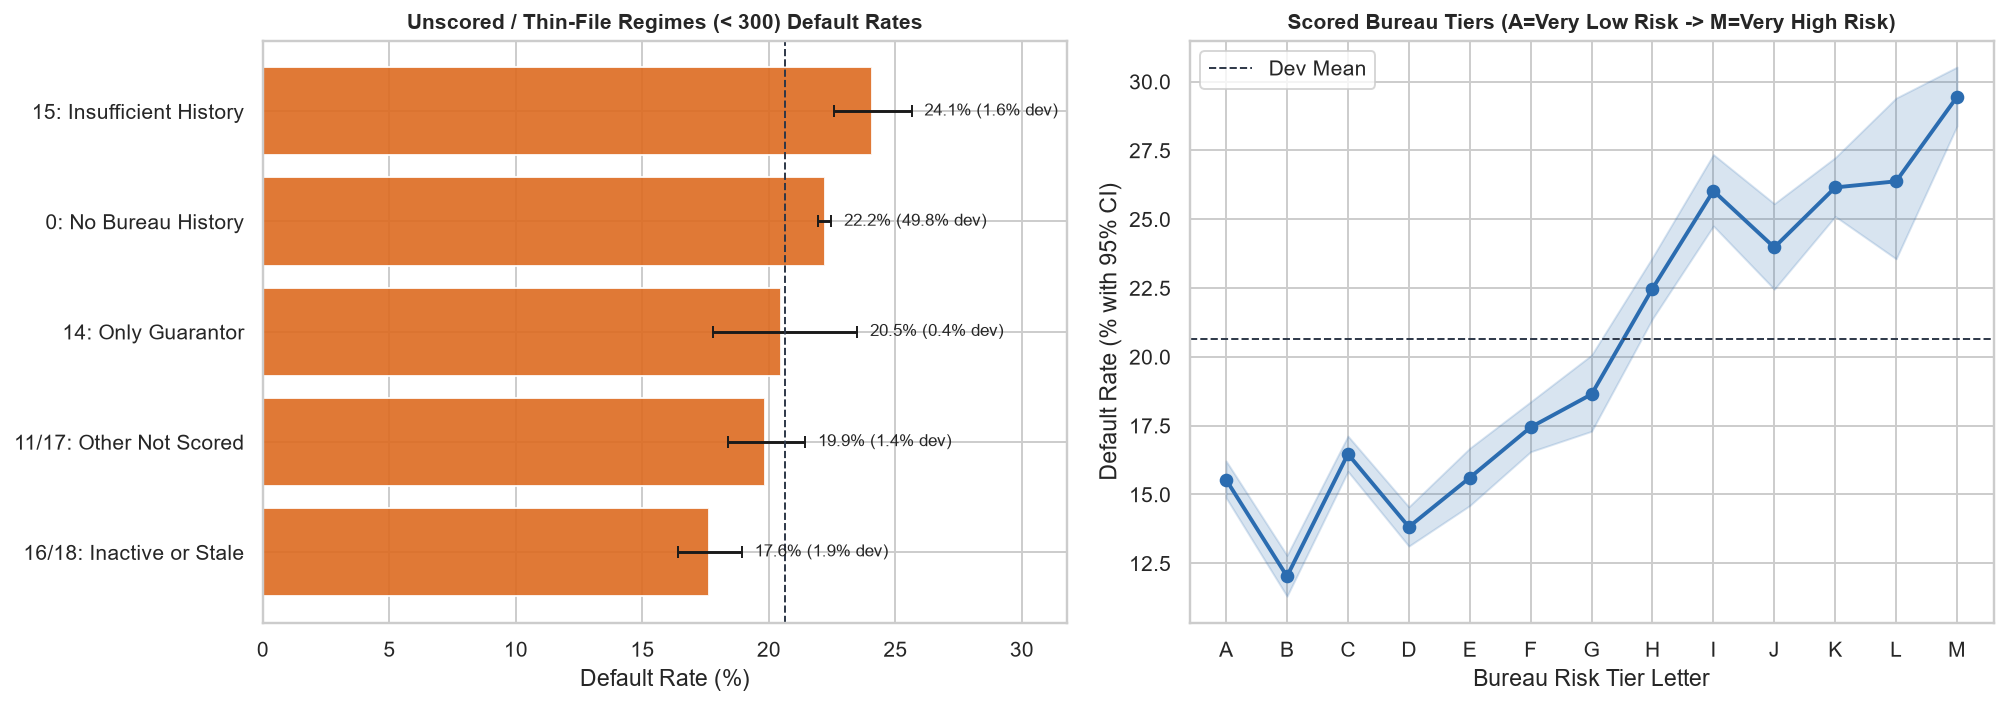

In [6]:
sc = dev["PERFORM_CNS.SCORE"]
desc_s = dev["PERFORM_CNS.SCORE.DESCRIPTION"].fillna("").astype(str)
dev["bureau_plot_grp"] = np.select(
    [
        sc >= 300,
        desc_s.str.contains("No Bureau History", case=False, na=False),
        desc_s.str.contains("Guarantor", case=False, na=False),
        desc_s.str.contains("Sufficient History", case=False, na=False),
        desc_s.str.contains("Inactive|36 months", case=False, na=False),
    ],
    [
        desc_s,
        "0: No Bureau History",
        "14: Only Guarantor",
        "15: Insufficient History",
        "16/18: Inactive or Stale",
    ],
    default="11/17: Other Not Scored",
)
b_grp = dev.groupby("bureau_plot_grp").agg(n=("loan_default", "count"), k=("loan_default", "sum"), min_sc=("PERFORM_CNS.SCORE", "min")).reset_index()
b_grp["rate"] = b_grp["k"] / b_grp["n"] * 100.0
b_grp["share"] = b_grp["n"] / n_dev * 100.0

unscored_df = b_grp[b_grp["min_sc"] < 300].sort_values("rate")
scored_df = b_grp[b_grp["min_sc"] >= 300].copy()
scored_df["tier"] = scored_df["bureau_plot_grp"].str[0]
scored_df = scored_df.sort_values("tier")

fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.2))

lo_u, hi_u = wilson_ci(unscored_df["k"].to_numpy(), unscored_df["n"].to_numpy())
axes[0].barh(unscored_df["bureau_plot_grp"], unscored_df["rate"], xerr=[unscored_df["rate"] - lo_u*100, hi_u*100 - unscored_df["rate"]], capsize=3, color="#dd6b20", alpha=0.9)
axes[0].axvline(dev_default_rate * 100, color="#2d3748", linestyle="--", linewidth=1.0)
axes[0].set_title("Unscored / Thin-File Regimes (< 300) Default Rates")
axes[0].set_xlabel("Default Rate (%)")
axes[0].set_xlim(0, unscored_df["rate"].max() * 1.32)
for i, r in enumerate(unscored_df.itertuples()):
    axes[0].text(r.rate + (hi_u[i]*100 - r.rate) + 0.5, i, f"{r.rate:.1f}% ({r.share:.1f}% dev)", va="center", fontsize=8.5)

lo_sc, hi_sc = wilson_ci(scored_df["k"].to_numpy(), scored_df["n"].to_numpy())
axes[1].plot(scored_df["tier"], scored_df["rate"], marker="o", color="#2b6cb0", linewidth=2.0)
axes[1].fill_between(scored_df["tier"], lo_sc * 100, hi_sc * 100, color="#2b6cb0", alpha=0.18)
axes[1].axhline(dev_default_rate * 100, color="#2d3748", linestyle="--", linewidth=1.0, label="Dev Mean")
axes[1].set_title("Scored Bureau Tiers (A=Very Low Risk -> M=Very High Risk)")
axes[1].set_xlabel("Bureau Risk Tier Letter")
axes[1].set_ylabel("Default Rate (% with 95% CI)")
axes[1].legend(loc="upper left")

fig.tight_layout()
fig.savefig(FIG_DIR / "eda_04_bureau_regime_and_score_risk.png", bbox_inches="tight")
plt.show()

**Diễn giải Hình `eda_04_bureau_regime_and_score_risk.png`:**
- **Biểu đồ cho thấy gì:** Hai chế độ điểm Bureau hoàn toàn khác nhau: (1) nhóm `< 300` (chiếm hơn nửa tập Dev) phân hóa rõ giữa `Inactive/Stale (~17.6%)` và `Insufficient History (~24.2%)` / `No History (~22.1%)`; (2) trong nhóm có điểm thực `>= 300`, tỷ lệ vỡ nợ tăng gần như đơn điệu từ hạng `A/B (~12–15%)` lên tới hạng `M (~29–30%)`.
- **Tại sao quan trọng:** Chứng minh trực tiếp tính đúng đắn của việc thiết kế cặp đặc trưng tách chế độ: `has_bureau_score`, `bureau_score_clean`, `bureau_unscored_group` và `bureau_risk_ordinal` (`1..13`), tránh để mô hình tuyến tính bị méo do bước nhảy giữa mã `0–18` và điểm `300–890`.
- **Có thể và KHÔNG thể kết luận gì:** Có thể khẳng định việc tách riêng phân đoạn `thin-file (<300)` khỏi thang điểm `300–890` là cần thiết về mặt thống kê. **Không thể kết luận** việc không có lịch sử tín dụng luôn tốt hơn hay xấu hơn người có lịch sử — hạng `A–G` an toàn hơn nhóm không lịch sử, trong khi hạng `H–M` lại rủi ro hơn rõ rệt.

## 5. Quan Hệ Biến–Mục Tiêu Phi Tuyến và Tương Tác Đòn Bẩy × Điểm Tín Dụng

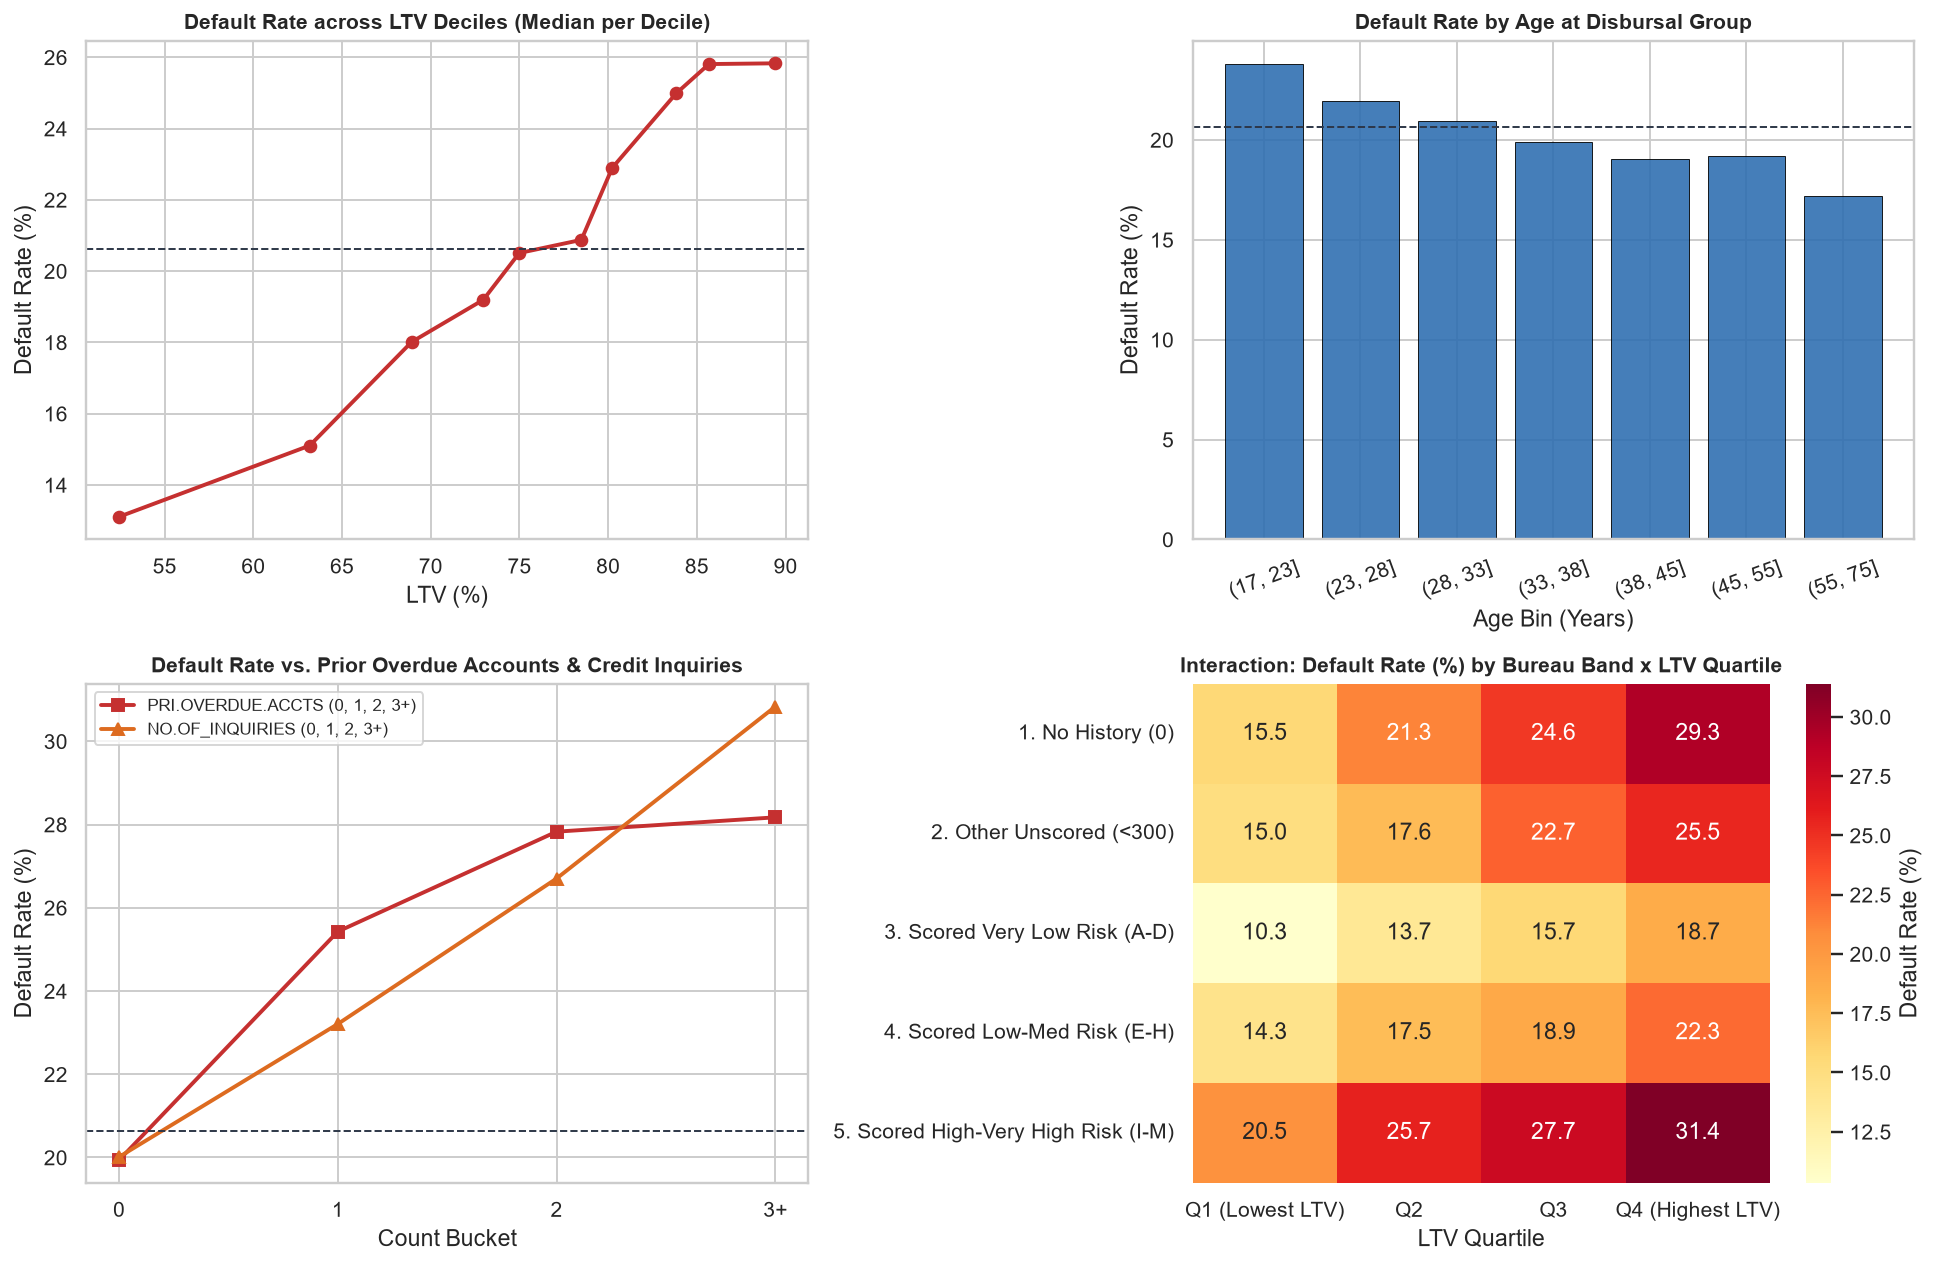

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14.0, 9.2))

# Top-left: LTV deciles
dev["ltv_decile"] = pd.qcut(dev["ltv"], q=10, duplicates="drop")
ltv_g = dev.groupby("ltv_decile", observed=False).agg(n=("loan_default", "count"), k=("loan_default", "sum"), med=("ltv", "median")).reset_index()
ltv_g["rate"] = ltv_g["k"] / ltv_g["n"] * 100.0
axes[0, 0].plot(ltv_g["med"], ltv_g["rate"], marker="o", color="#c53030", linewidth=2.0)
axes[0, 0].axhline(dev_default_rate * 100, color="#2d3748", linestyle="--", linewidth=1.0)
axes[0, 0].set_title("Default Rate across LTV Deciles (Median per Decile)")
axes[0, 0].set_xlabel("LTV (%)")
axes[0, 0].set_ylabel("Default Rate (%)")

# Top-right: Age buckets
dev["age_bin"] = pd.cut(dev["age_at_disbursal"], bins=[17, 23, 28, 33, 38, 45, 55, 75])
age_g = dev.groupby("age_bin", observed=False).agg(n=("loan_default", "count"), k=("loan_default", "sum")).reset_index()
age_g["rate"] = age_g["k"] / age_g["n"] * 100.0
axes[0, 1].bar(age_g["age_bin"].astype(str), age_g["rate"], color="#2b6cb0", alpha=0.88, edgecolor="black", linewidth=0.5)
axes[0, 1].axhline(dev_default_rate * 100, color="#2d3748", linestyle="--", linewidth=1.0)
axes[0, 1].set_title("Default Rate by Age at Disbursal Group")
axes[0, 1].set_xlabel("Age Bin (Years)")
axes[0, 1].set_ylabel("Default Rate (%)")
axes[0, 1].tick_params(axis="x", rotation=20)

# Bottom-left: Prior Overdue & Recent Inquiries buckets
ovd_bins = pd.cut(dev["PRI.OVERDUE.ACCTS"], bins=[-1, 0, 1, 2, 100], labels=["0 Overdue", "1 Overdue", "2 Overdue", "3+ Overdue"])
inq_bins = pd.cut(dev["NO.OF_INQUIRIES"], bins=[-1, 0, 1, 2, 100], labels=["0 Inq", "1 Inq", "2 Inq", "3+ Inq"])
ovd_r = dev.groupby(ovd_bins, observed=False)["loan_default"].mean() * 100.0
inq_r = dev.groupby(inq_bins, observed=False)["loan_default"].mean() * 100.0
x_b = np.arange(4)
axes[1, 0].plot(x_b, ovd_r.values, marker="s", linewidth=2.0, color="#c53030", label="PRI.OVERDUE.ACCTS (0, 1, 2, 3+)")
axes[1, 0].plot(x_b, inq_r.values, marker="^", linewidth=2.0, color="#dd6b20", label="NO.OF_INQUIRIES (0, 1, 2, 3+)")
axes[1, 0].axhline(dev_default_rate * 100, color="#2d3748", linestyle="--", linewidth=1.0)
axes[1, 0].set_xticks(x_b)
axes[1, 0].set_xticklabels(["0", "1", "2", "3+"])
axes[1, 0].set_title("Default Rate vs. Prior Overdue Accounts & Credit Inquiries")
axes[1, 0].set_xlabel("Count Bucket")
axes[1, 0].set_ylabel("Default Rate (%)")
axes[1, 0].legend(fontsize=8.5)

# Bottom-right: 2D interaction heatmap (LTV Quartile x Bureau Regime)
sc_b = dev["PERFORM_CNS.SCORE"]
tier_char = dev["PERFORM_CNS.SCORE.DESCRIPTION"].fillna("").astype(str).str.strip().str[0].str.upper()
dev["bureau_band"] = np.select(
    [
        sc_b == 0,
        sc_b < 300,
        tier_char.isin(["A", "B", "C", "D"]),
        tier_char.isin(["E", "F", "G", "H"]),
    ],
    [
        "1. No History (0)",
        "2. Other Unscored (<300)",
        "3. Scored Very Low Risk (A-D)",
        "4. Scored Low-Med Risk (E-H)",
    ],
    default="5. Scored High-Very High Risk (I-M)",
)
dev["ltv_q"] = pd.qcut(dev["ltv"], q=4, labels=["Q1 (Lowest LTV)", "Q2", "Q3", "Q4 (Highest LTV)"])
hm = dev.pivot_table(index="bureau_band", columns="ltv_q", values="loan_default", aggfunc="mean", observed=False) * 100.0
sns.heatmap(hm, annot=True, fmt=".1f", cmap="YlOrRd", ax=axes[1, 1], cbar_kws={"label": "Default Rate (%)"})
axes[1, 1].set_title("Interaction: Default Rate (%) by Bureau Band x LTV Quartile")
axes[1, 1].set_xlabel("LTV Quartile")
axes[1, 1].set_ylabel("")

fig.tight_layout()
fig.savefig(FIG_DIR / "eda_05_feature_target_relationships.png", bbox_inches="tight")
plt.show()

**Diễn giải Hình `eda_05_feature_target_relationships.png`:**
- **Biểu đồ cho thấy gì:** Tỷ lệ vỡ nợ tăng mạnh theo hướng phi tuyến khi `ltv` vượt qua vùng `75%–85%`, giảm dần theo độ tuổi đến nhóm trung niên rồi ổn định, tăng dốc theo số tài khoản quá hạn `PRI.OVERDUE.ACCTS` và số lần tra cứu tín dụng `NO.OF_INQUIRIES`. Ở bản đồ nhiệt 2 chiều, khách hàng vừa nằm ở `LTV Q4` vừa thuộc nhóm `Scored I–M` hoặc `No History` có tỷ lệ vỡ nợ cao hơn gấp đôi nhóm `LTV Q1 + Scored A–D`.
- **Tại sao quan trọng:** Cung cấp bằng chứng trực quan hỗ trợ các đặc trưng tỷ số (`overdue_to_total_ratio`, `inquiry_to_accts_ratio`) và biến tương tác `ltv_x_no_bureau`, đồng thời giải thích vì sao mô hình phi tuyến (GBDT) có lợi thế trước hồi quy tuyến tính đơn thuần.
- **Có thể và KHÔNG thể kết luận gì:** Có thể kết luận tồn tại hiệu ứng ngưỡng và tương tác rõ nét giữa đòn bẩy vay và hồ sơ tín dụng. **Không thể kết luận** rằng hạ LTV sẽ tự động làm giảm tỷ lệ vỡ nợ theo quan hệ nhân quả trực tiếp (vì người vay chấp nhận LTV rất cao có thể vốn đã có đặc điểm thu nhập/thanh khoản yếu hơn).

## 6. Tương Quan Đa Biến và Đặc Trưng Dư Thừa / Đa Cộng Tuyến

Saved Dev EDA summary to reports/tables/m3_dev_eda_summary.json


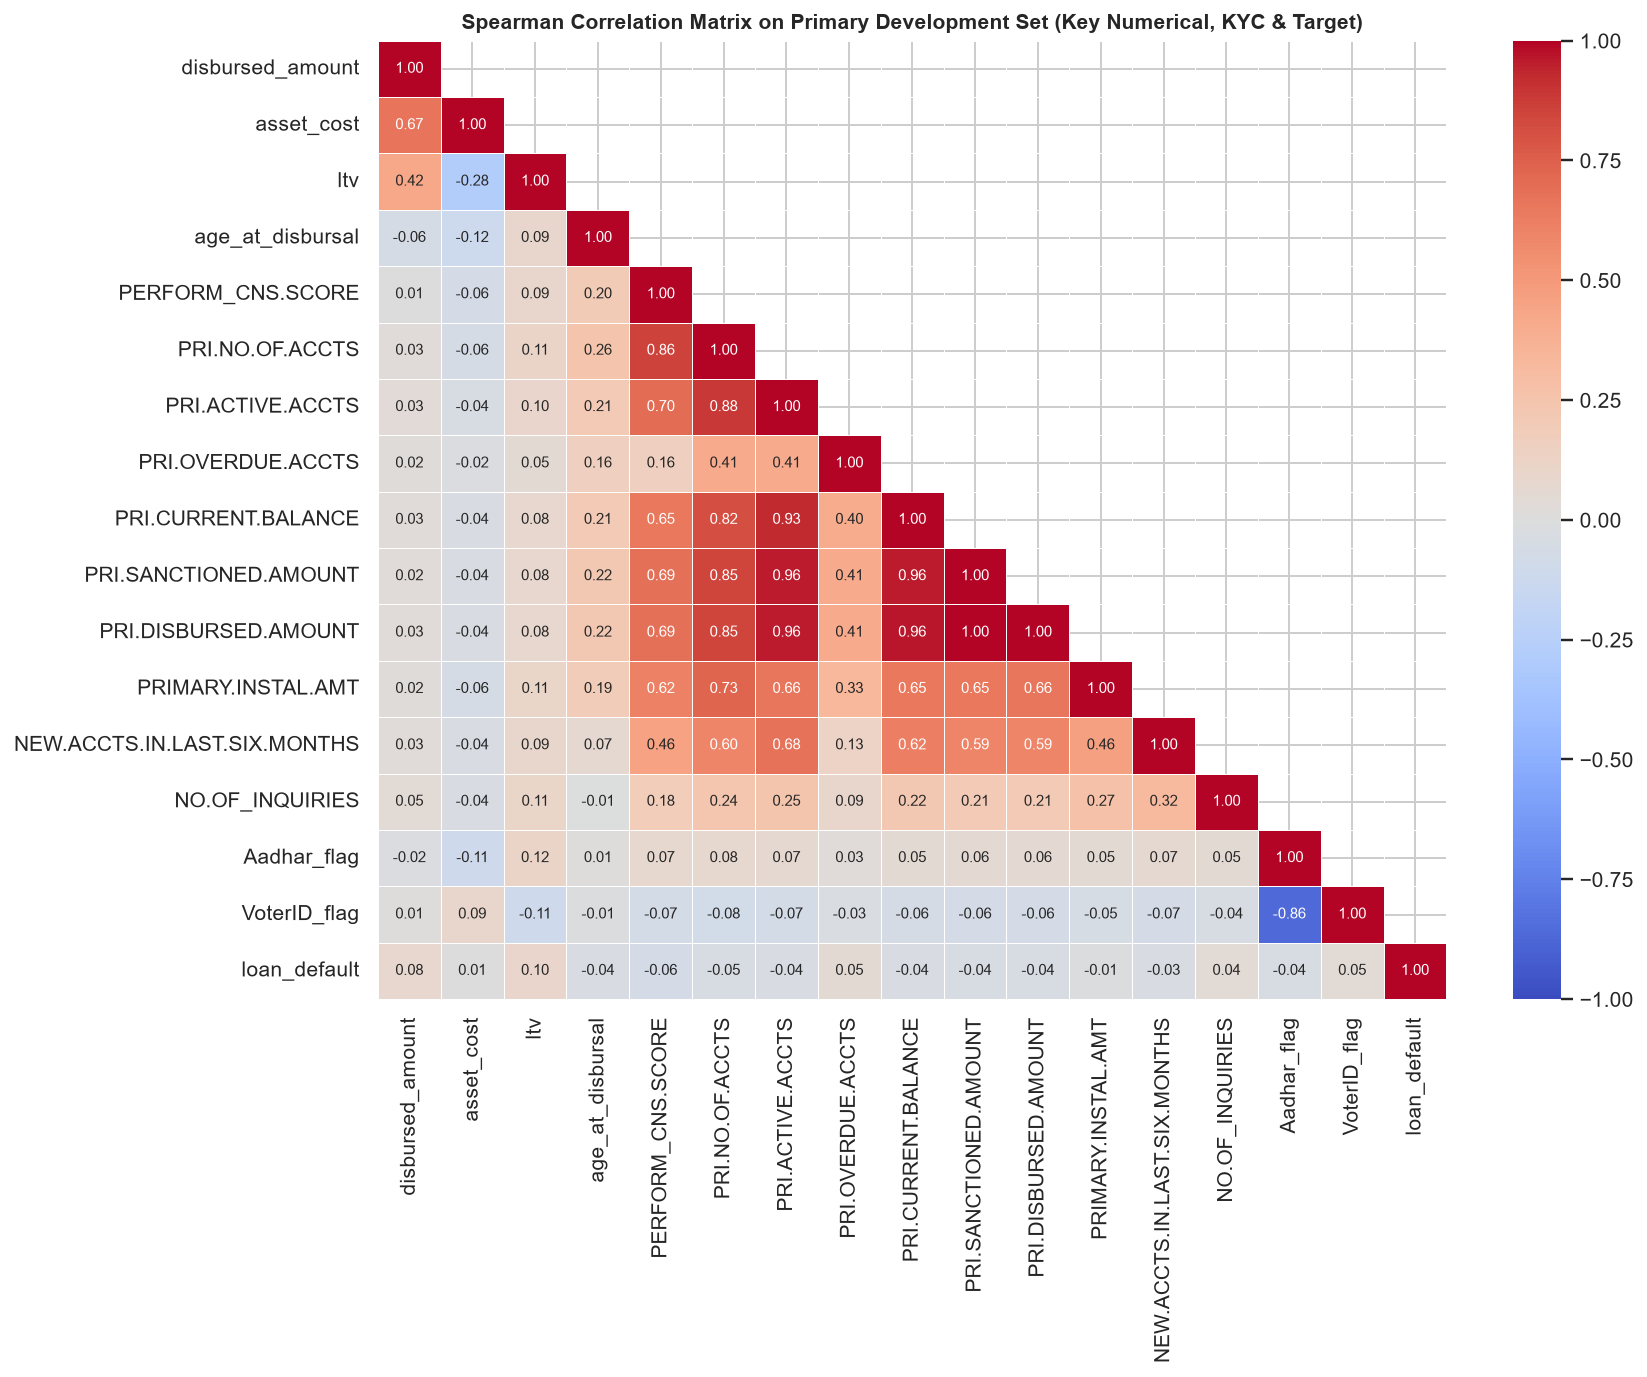

In [8]:
corr_cols = [
    "disbursed_amount", "asset_cost", "ltv", "age_at_disbursal",
    "PERFORM_CNS.SCORE", "PRI.NO.OF.ACCTS", "PRI.ACTIVE.ACCTS", "PRI.OVERDUE.ACCTS",
    "PRI.CURRENT.BALANCE", "PRI.SANCTIONED.AMOUNT", "PRI.DISBURSED.AMOUNT",
    "PRIMARY.INSTAL.AMT", "NEW.ACCTS.IN.LAST.SIX.MONTHS", "NO.OF_INQUIRIES",
    "Aadhar_flag", "VoterID_flag", "loan_default",
]
corr_mat = dev[corr_cols].corr(method="spearman")

fig, ax = plt.subplots(figsize=(12.5, 10.0))
mask = np.triu(np.ones_like(corr_mat, dtype=bool), k=1)
sns.heatmap(corr_mat, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, linewidths=0.4, annot_kws={"size": 7.5}, ax=ax)
ax.set_title("Spearman Correlation Matrix on Primary Development Set (Key Numerical, KYC & Target)")
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_06_correlation_and_redundancy.png", bbox_inches="tight")
plt.show()

# Persist machine-readable Dev EDA summary for docs/eda_report.md
eda_summary = {
    "dev_rows": n_dev,
    "dev_defaults": n_pos_dev,
    "dev_non_defaults": n_neg_dev,
    "dev_default_rate_pct": round(dev_default_rate * 100, 4),
    "dev_date_min": str(dev["disb_dt"].min().date()),
    "dev_date_max": str(dev["disb_dt"].max().date()),
    "numerical_summary": num_summary,
    "employment_summary": emp[["Employment.Type_clean", "n", "k", "rate"]].to_dict(orient="records"),
    "ltv_decile_rates": ltv_g[["med", "n", "rate"]].to_dict(orient="records"),
    "interaction_heatmap_pct": hm.round(2).to_dict(),
    "key_correlations": {
        "PRI.SANCTIONED_vs_PRI.DISBURSED": round(float(corr_mat.loc["PRI.SANCTIONED.AMOUNT", "PRI.DISBURSED.AMOUNT"]), 4),
        "Aadhar_vs_VoterID": round(float(corr_mat.loc["Aadhar_flag", "VoterID_flag"]), 4),
        "disbursed_vs_asset_cost": round(float(corr_mat.loc["disbursed_amount", "asset_cost"]), 4),
    },
}
(TABLES_DIR / "m3_dev_eda_summary.json").write_text(json.dumps(eda_summary, indent=2, ensure_ascii=False), encoding="utf-8")
print("Saved Dev EDA summary to reports/tables/m3_dev_eda_summary.json")

**Diễn giải Hình `eda_06_correlation_and_redundancy.png`:**
- **Biểu đồ cho thấy gì:** Trên Development Set xuất hiện 3 cụm tương quan mạnh: (i) `PRI.SANCTIONED.AMOUNT` và `PRI.DISBURSED.AMOUNT` gần như đồng nhất ($ho pprox 0.996$), kéo theo `PRI.CURRENT.BALANCE` và `PRI.ACTIVE.ACCTS` ($ho > 0.92$); (ii) `Aadhar_flag` và `VoterID_flag` tương quan nghịch rất mạnh ($ho pprox -0.87$) vì người vay thường chỉ nộp một trong hai giấy tờ chính; (iii) `disbursed_amount` và `asset_cost` tương quan thuận ($ho pprox 0.67$).
- **Tại sao quan trọng:** Giúp quyết định hợp lý bước chọn lọc biến cho mô hình tuyến tính (`drop_redundant=True` loại cặp `PRI.DISBURSED.AMOUNT` / `SEC.DISBURSED.AMOUNT` trùng lắp gần tuyệt đối, đồng thời giải thích vì sao cần cẩn trọng khi đọc SHAP/hệ số trên khối `PRI.*` ở Milestone 5).
- **Có thể và KHÔNG thể kết luận gì:** Có thể kết luận mức độ dư thừa thông tin tuyến tính/đơn điệu cao bên trong khối `PRI.*` và `SEC.*`. **Không thể kết luận** rằng sự chênh lệch nhỏ giữa `SANCTIONED` và `DISBURSED` (hoặc `CURRENT.BALANCE > SANCTIONED`) vô dụng ở mô hình phi tuyến — thực tế kiểm toán M1 đã thấy chính những trường hợp lệch này mang tín hiệu rủi ro riêng biệt.